In [2]:
import glob, os
import numpy as np
import pandas as pd
import pyspark
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

spark = pyspark.sql.SparkSession.builder.appName("dev").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

def read_gold(folder):
    files = sorted(glob.glob(folder + "*.parquet"))
    return spark.read.parquet(*files).toPandas()

stab = read_gold("datamart/gold/model_monitoring/stability/")
perf = read_gold("datamart/gold/model_monitoring/performance/")
promo = pd.read_json("model_bank/promotion_log.jsonl", lines=True)

stab["snapshot_date"] = pd.to_datetime(stab["snapshot_date"])
perf["snapshot_date"] = pd.to_datetime(perf["snapshot_date"])
perf["cohort_month"] = pd.to_datetime(perf["cohort_month"])
promo["run_date"] = pd.to_datetime(promo["run_date"])
os.makedirs("charts", exist_ok=True)

print("stability rows:", len(stab), "| months:", stab["snapshot_date"].nunique())
print("performance rows:", len(perf), "| promotion log lines:", len(promo))

/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


stability rows: 776 | months: 16
performance rows: 10 | promotion log lines: 16


/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [3]:
INK, MUTED, ACCENT, GRID = "#2b2118", "#7a6f64", "#3d405b", "#e8e0d2"
WATCH, ACT = "#e09f3e", "#9e2a2b"          # status colours: reserved for watch / act only
PAPER = "#fbf8f3"

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Georgia", "Palatino", "Palatino Linotype", "Cambria", "DejaVu Serif"],
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "text.color": INK, "axes.labelcolor": MUTED,
})

def style(ax, title, ylabel=None, dates=None, rotate=False):
    ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED, length=0)
    if dates is not None:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
        ax.set_xticks(list(dates))
        if rotate:
            ax.tick_params(axis="x", rotation=45)

def switch_point(dates, versions):
    """x position (midway between two dates) where the model version first changes; None if it never does"""
    s = pd.Series(list(versions), index=list(dates)).sort_index()
    changed = (s != s.shift()).to_numpy().copy()
    changed[0] = False
    if not changed.any():
        return None
    i = int(np.argmax(changed))
    return s.index[i - 1] + (s.index[i] - s.index[i - 1]) / 2

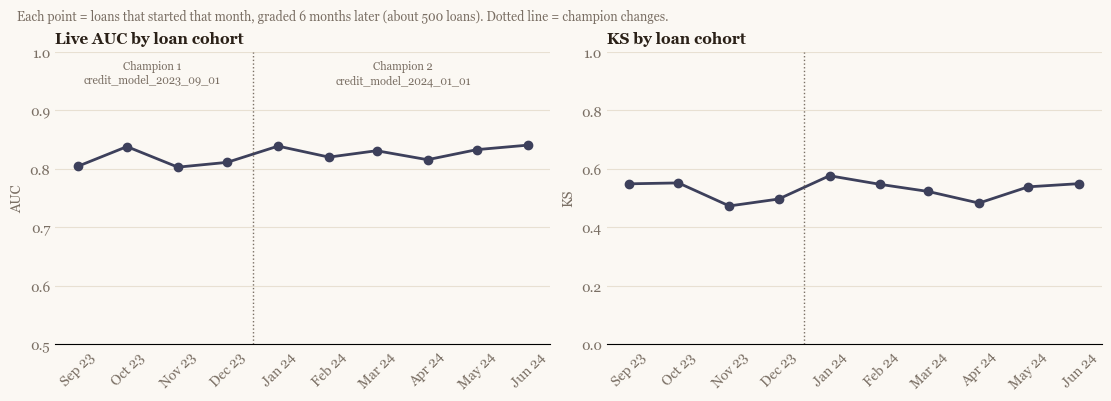

In [4]:
p = perf.sort_values("cohort_month").reset_index(drop=True)
sw = switch_point(p["cohort_month"], p["scoring_model_version"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), constrained_layout=True)

a1.plot(p["cohort_month"], p["auc"], color=ACCENT, lw=2, marker="o", ms=6)
a1.set_ylim(0.5, 1.0)
style(a1, "Live AUC by loan cohort", "AUC", p["cohort_month"], rotate=True)

# name the champion that scored each stretch of cohorts
runs = p.groupby("scoring_model_version", sort=False).agg(first=("cohort_month", "min"), last=("cohort_month", "max"))
for i, (name, r) in enumerate(runs.iterrows(), start=1):
    mid = r["first"] + (r["last"] - r["first"]) / 2
    a1.text(mid, 0.985, f"Champion {i}\n{name}", color=MUTED, fontsize=8, ha="center", va="top")

a2.plot(p["cohort_month"], p["ks"], color=ACCENT, lw=2, marker="o", ms=6)
a2.set_ylim(0.0, 1.0)
style(a2, "KS by loan cohort", "KS", p["cohort_month"], rotate=True)

if sw is not None:
    for ax in (a1, a2):
        ax.axvline(sw, color=MUTED, lw=1, ls=":")

fig.suptitle("Each point = loans that started that month, graded 6 months later (about 500 loans). Dotted line = champion changes.",
             x=0.01, ha="left", fontsize=9, color=MUTED)
plt.savefig("charts/performance.png", dpi=200, bbox_inches="tight")
plt.show()

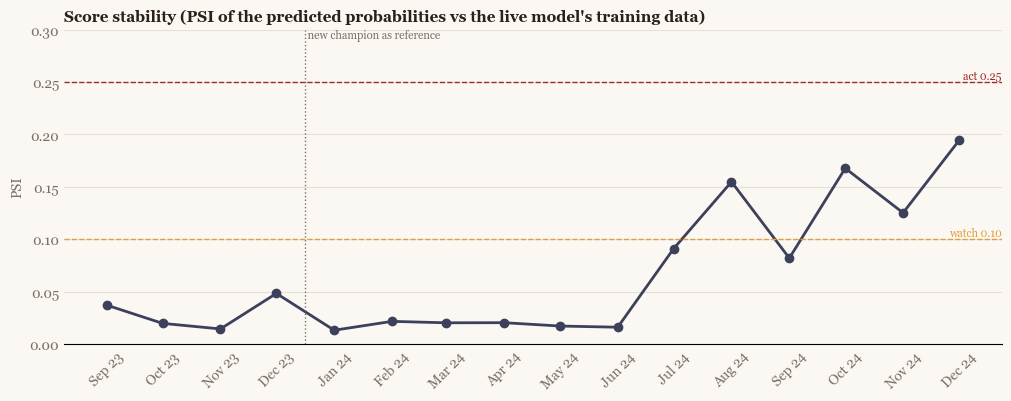

In [5]:
def series(feature, metric=None):
    d = stab[stab["feature"] == feature]
    if metric:
        d = d[d["metric"] == metric]
    return d.set_index("snapshot_date")["value"].sort_index()

score_psi = series("model_score")
ref_ver = stab.groupby("snapshot_date")["model_version"].first().sort_index()
months = score_psi.index
sw = switch_point(ref_ver.index, ref_ver.values)

fig, ax = plt.subplots(figsize=(10, 3.9), constrained_layout=True)

ax.plot(months, score_psi, color=ACCENT, lw=2, marker="o", ms=6)
ax.axhline(0.10, color=WATCH, lw=1, ls="--")
ax.axhline(0.25, color=ACT, lw=1, ls="--")
ax.annotate("watch 0.10", xy=(1.0, 0.10), xycoords=("axes fraction", "data"), ha="right", va="bottom", fontsize=8, color=WATCH)
ax.annotate("act 0.25", xy=(1.0, 0.25), xycoords=("axes fraction", "data"), ha="right", va="bottom", fontsize=8, color=ACT)
ax.set_ylim(0, max(0.30, float(score_psi.max()) * 1.15))
style(ax, "Score stability (PSI of the predicted probabilities vs the live model's training data)", "PSI", months, rotate=True)

if sw is not None:
    ax.axvline(sw, color=MUTED, lw=1, ls=":")
    ax.text(sw, ax.get_ylim()[1], " new champion as reference", color=MUTED, fontsize=8, va="top")

plt.savefig("charts/stability.png", dpi=200, bbox_inches="tight")
plt.show()

/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


        predicted  actual    n
decile                        
1           0.036   0.036  494
2           0.068   0.061  494
3           0.099   0.101  493
4           0.134   0.142  494
5           0.176   0.162  494
6           0.236   0.219  493
7           0.329   0.328  494
8           0.462   0.454  493
9           0.623   0.613  494
10          0.814   0.806  494
overall: predicted 0.298 | actual 0.292 | loans 4937


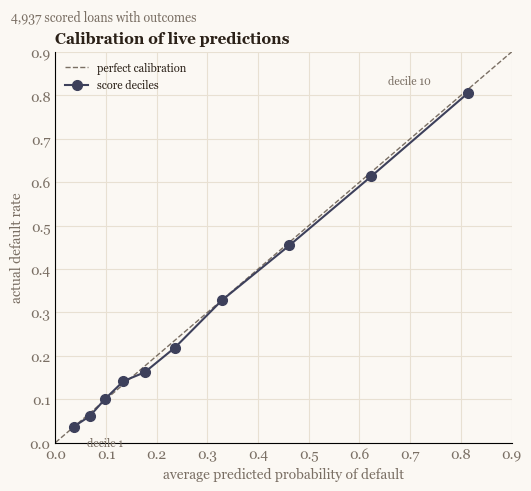

In [6]:
pred = read_gold("datamart/gold/model_predictions/")[["loan_id", "model_predictions"]]
lab = read_gold("datamart/gold/label_store/")[["loan_id", "label"]]
cal = pred.merge(lab, on="loan_id")
cal["label"] = cal["label"].astype(float)
cal["decile"] = pd.qcut(cal["model_predictions"], 10, labels=False) + 1
tab = cal.groupby("decile").agg(predicted=("model_predictions", "mean"), actual=("label", "mean"), n=("label", "size"))
print(tab.round(3))
print("overall: predicted", round(cal["model_predictions"].mean(), 3), "| actual", round(cal["label"].mean(), 3), "| loans", len(cal))

fig, ax = plt.subplots(figsize=(5.2, 4.8), constrained_layout=True)
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="perfect calibration")
ax.plot(tab["predicted"], tab["actual"], color=ACCENT, lw=1.5, marker="o", ms=7, label="score deciles")
for d in (1, 10):
    ax.annotate(f"decile {d}", (tab.loc[d, "predicted"], tab.loc[d, "actual"]), textcoords="offset points",
                xytext=(10, -14) if d == 1 else (-58, 6), fontsize=8, color=MUTED)
ax.set_xlim(0, 0.9)
ax.set_ylim(0, 0.9)
ax.set_xlabel("average predicted probability of default", color=MUTED)
ax.set_ylabel("actual default rate", color=MUTED)
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Calibration of live predictions", loc="left", fontsize=11, color=INK, fontweight="bold")
fig.suptitle(f"{len(cal):,} scored loans with outcomes", x=0.01, ha="left", fontsize=9, color=MUTED)
plt.savefig("charts/calibration.png", dpi=200, bbox_inches="tight")
plt.show()

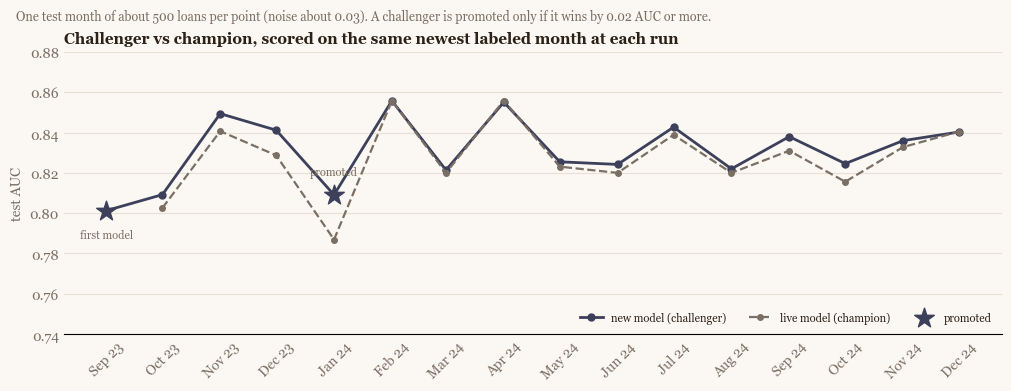

In [7]:
pm = promo.sort_values("run_date").reset_index(drop=True)
won = pm[pm["promoted"]]

fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(pm["run_date"], pm["challenger_test_auc"], color=ACCENT, lw=2, marker="o", ms=5, label="new model (challenger)")
ax.plot(pm["run_date"], pm["champion_test_auc"], color=MUTED, lw=1.6, ls="--", marker="o", ms=4, label="live model (champion)")
ax.scatter(won["run_date"], won["challenger_test_auc"], marker="*", s=220, color=ACCENT, zorder=5, label="promoted")
for _, r in won.iterrows():
    first = r["champion_test_auc"] != r["champion_test_auc"]      # no champion yet -> first model
    ax.annotate("first model" if first else "promoted", (r["run_date"], r["challenger_test_auc"]),
                textcoords="offset points", xytext=(0, -20) if first else (0, 14), ha="center",
                fontsize=8, color=MUTED)
ax.set_ylim(0.74, 0.88)
ax.legend(frameon=False, fontsize=8, loc="lower right", ncol=3)
style(ax, "Challenger vs champion, scored on the same newest labeled month at each run", "test AUC", pm["run_date"], rotate=True)
fig.suptitle("One test month of about 500 loans per point (noise about 0.03). A challenger is promoted only if it wins by 0.02 AUC or more.",
             x=0.01, ha="left", fontsize=9, color=MUTED)
plt.savefig("charts/model_timeline.png", dpi=200, bbox_inches="tight")
plt.show()

/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.3.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.3.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/sabalal/venvs/jupyter/lib/python3.14/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.3.2 when 

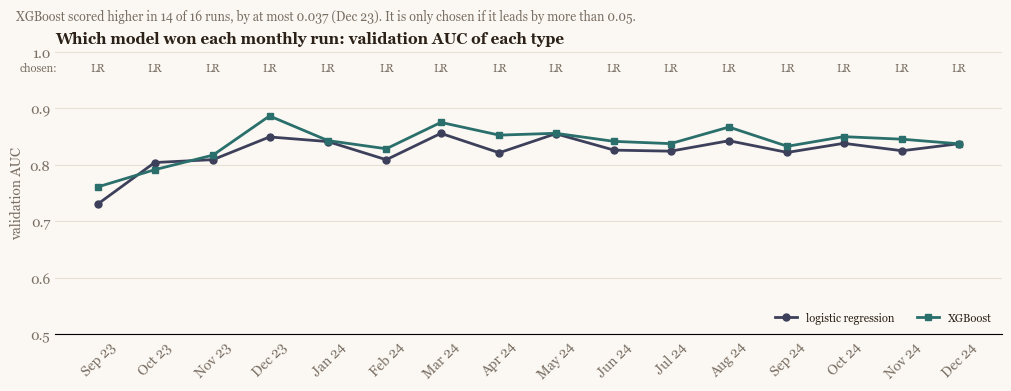

In [8]:
import pickle, glob

sel = []
for f in sorted(glob.glob("model_bank/credit_model_*.pkl")):
    with open(f, "rb") as fh:
        art = pickle.load(fh)
    s = art["selection"]
    sel.append({"run_date": pd.to_datetime(art["model_version"][-10:].replace("_", "-")),
                "chosen": s["chosen"], "lr": s["val_auc_by_candidate"]["lr"], "xgb": s["val_auc_by_candidate"]["xgb"]})
sel = pd.DataFrame(sel).sort_values("run_date").reset_index(drop=True)
sel["lead"] = sel["xgb"] - sel["lr"]
TEAL = "#2a6f6b"

fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(sel["run_date"], sel["lr"], color=ACCENT, lw=2, marker="o", ms=5, label="logistic regression")
ax.plot(sel["run_date"], sel["xgb"], color=TEAL, lw=2, marker="s", ms=5, label="XGBoost")
for _, r in sel.iterrows():
    ax.text(r["run_date"], 0.965, "LR" if r["chosen"] == "lr" else "XGB", ha="center", fontsize=8, color=MUTED)
ax.text(sel["run_date"].iloc[0] - pd.Timedelta(days=22), 0.965, "chosen:", ha="right", fontsize=8, color=MUTED)
ax.set_ylim(0.5, 1.0)
ax.legend(frameon=False, fontsize=8, loc="lower right", ncol=2)
style(ax, "Which model won each monthly run: validation AUC of each type", "validation AUC", sel["run_date"], rotate=True)
top = sel.loc[sel["lead"].idxmax()]
fig.suptitle(f"XGBoost scored higher in {int((sel['lead'] > 0).sum())} of {len(sel)} runs, by at most {top['lead']:.3f} "
             f"({top['run_date']:%b %y}). It is only chosen if it leads by more than 0.05.",
             x=0.01, ha="left", fontsize=9, color=MUTED)
plt.savefig("charts/model_choice.png", dpi=200, bbox_inches="tight")
plt.show()